# D1 · Basic Contrast Mechanisms

**Part:** D – Contrast · **Reading time:** ~75 min · **Pass 1 overview:** [P1.4 Contrast and Image Quality](../pass1_big_picture/P1.4_Contrast_and_Image_Quality.ipynb) · **Refreshers you may want:** [RM1 ODEs for MRI](../refreshers/RM1_ODEs_for_MRI.ipynb), [RM2 Complex numbers and rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)

**Why this chapter matters.** An MRI image is not a photograph of anatomy: the brightness of every pixel is a *formula* that combines tissue properties ($M_0$, $T_1$, $T_2$) with numbers that **you** choose on the scanner (TE, TR, flip angle, TI). The same brain can make cerebrospinal fluid white, black or grey. That freedom – arguably MRI's biggest advantage over CT or ultrasound – is only useful if you understand the formulas. In this chapter we derive them step by step from the relaxation equations, check them against a Bloch simulation, and use them to design $T_1$-, $T_2$- and proton-density-weighted images, inversion recovery (STIR, FLAIR) and spoiled gradient echoes (Ernst angle).

![MRI is a modality with multiple contrasts: the same anatomy can look very different depending on the sequence parameters](../images/3DMagic.gif)

*The same head imaged with several different contrasts (animation from the original book).*

## Learning goals

1. Describe how various types of MRI contrast are created
    * Describe how $T_1$-, $T_2$- and proton-density (PD) weighted images are formed
    * Describe how inversion recovery works, and compute the inversion time that nulls a tissue (STIR, FLAIR)
2. Manipulate MRI sequence parameters to improve performance
    * Choose flip angle, TE, TR and TI for a desired contrast
3. *(added)* Derive the saturation-recovery, spin-echo, spoiled-gradient-echo and inversion-recovery signal equations from the relaxation solutions, including the steady-state argument
4. *(added)* Derive the Ernst angle, and distinguish "maximum signal" from "maximum contrast" and from "maximum contrast-to-noise per unit time"
5. *(added)* Explain what "spoiling" assumes and check it with a Bloch simulation

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec M=[M_x,M_y,M_z]^T$ | net magnetization (rotating frame) | A/m, normalized $M_0=1$ | |
| $M_z$ | longitudinal magnetization (along $B_0$) | same as $M$ | |
| $M_{xy}=M_x+iM_y$ | transverse magnetization as a complex number | same | only this part induces signal |
| $M_0$ | equilibrium magnetization ∝ proton density ("PD") | same | relative: WM 0.7, GM 0.8, CSF 1.0 |
| $M_z^-(n)$, $M_z^+(n)$ | $M_z$ just **before** / just **after** the $n$-th RF pulse | same | |
| $M_{z,ss}$ | steady-state value of $M_z^-$ | same | |
| $T_1$ | longitudinal relaxation **time constant** | s | 0.25–4 s |
| $T_2$ | transverse relaxation time constant | s | 0.04–2 s in soft tissue/fluid |
| $T_2^*$ | effective transverse decay time incl. field inhomogeneity ($T_2^*\le T_2$) | s | see [D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb) |
| $R_1=1/T_1$, $R_2=1/T_2$ | relaxation **rates** | s⁻¹ | |
| $TE$ | echo time: centre of excitation → centre of k-space acquisition | s | 2–120 ms |
| $TR$ | repetition time between successive excitations | s | 3 ms – 10 s |
| $TI$ | inversion time: centre of 180° inversion pulse → excitation | s | 0.1–2.5 s |
| $\theta$ | flip angle of the excitation pulse | rad (or °) | 1°–90° |
| $\theta_E$ | Ernst angle (flip angle of maximum spoiled-GRE signal) | rad | |
| $E_1=e^{-TR/T_1}$, $E_2=e^{-TR/T_2}$ | shorthand used in steady-state formulas | – | between 0 and 1 |
| $S$ | signal (magnitude of $M_{xy}$ at TE, up to receiver scaling) | a.u. | |
| $C_{AB}=S_A-S_B$ | contrast between tissues A and B | a.u. | |
| $\sigma_n$ | noise standard deviation in the image | a.u. | |
| $CNR=|S_A-S_B|/\sigma_n$ | contrast-to-noise ratio | – | |
| $T_{scan}$ | scan time | s | |
| $n$ | pulse (repetition) index | – | |
| $t$ | time | s | |
| $\tau_c$ | correlation time of molecular motion (BPP model) | s | ps (water) … µs (solids) |
| $\omega_0=2\pi f_0$, $f_0=\bar\gamma B_0$ | Larmor angular frequency / frequency | rad/s, Hz | 63.9 MHz @1.5 T, 127.7 MHz @3 T |
| $\bar\gamma$ | gyromagnetic ratio $\gamma/2\pi$ | Hz/T | 42.58 MHz/T (¹H) |
| $B_0$ | main magnetic field | T | 1.5 T, 3 T |
| $\phi_n$ | RF phase of pulse $n$ (RF spoiling) | rad | $\phi_n=\phi_0\,n(n+1)/2$, $\phi_0=117°$ |
| $\Delta f$ | off-resonance frequency of an isochromat | Hz | |

> **⚠️ Common confusion:** $T_1$ and $T_2$ are **time constants** (seconds), not rates. The rates are $R_1=1/T_1$ and $R_2=1/T_2$ (s⁻¹). The original text sometimes called them "relaxation rates". Also: the letter $T$ alone is temperature, "T" after a number is tesla.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. What "contrast" means

A tissue is invisible in MRI unless its signal differs from that of its neighbours. We call

$$C_{AB} = S_A - S_B$$

the **contrast** between tissue A and tissue B.

*In words:* contrast is simply the difference of the two signals (sometimes normalized, e.g. $(S_A-S_B)/(S_A+S_B)$, called *relative contrast*),
where $S_A$, $S_B$ are the signals (pixel values, arbitrary units) of the two tissues.

A large contrast is useless if the image is noisy, so the quantity that really decides whether you can *see* a difference is the **contrast-to-noise ratio**

$$CNR_{AB} = \frac{|S_A - S_B|}{\sigma_n}.$$

*In words:* how many noise standard deviations separate the two tissues,
where $\sigma_n$ is the standard deviation of the image noise (same units as $S$). As a rule of thumb, a difference of a few $\sigma_n$ is needed to see it reliably (more for small objects).

Because noise averages down as $1/\sqrt{\text{number of averages}}$ (see [G2 Signal to Noise Ratio](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb)), the fair way to compare two protocols of different duration is the **CNR efficiency** $CNR/\sqrt{T_{scan}}$.

Every signal equation in this chapter has the form

$$S = \underbrace{M_0}_{\text{tissue: PD}}\;\cdot\;\underbrace{f_1(T_1;\,TR,\theta,TI)}_{\text{how much } M_z \text{ has recovered}}\;\cdot\;\underbrace{f_2(T_2\text{ or }T_2^*;\,TE)}_{\text{how much } M_{xy}\text{ has decayed}}$$

*In words:* the signal is the product of a proton-density factor, a $T_1$ factor controlled by TR (and flip angle / TI), and a $T_2$ factor controlled by TE. "Weighting" an image means choosing the sequence parameters so that one of these factors dominates the *differences* between tissues.

## 2. What determines $T_1$ and $T_2$ values?

$T_1$ and $T_2$ are intrinsic properties of a material, determined by the molecular environment and how the molecules move. A precise theory requires quantum mechanics (see [A3 In Vivo Spin Physics](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb)), but the typical patterns can be understood with one idea: **relaxation is driven by fluctuating magnetic fields from neighbouring nuclei, and it is efficient only if those fluctuations contain the right frequencies.**

Human tissues can roughly be grouped into classes with similar $T_1$ and $T_2$:

1. Liquids / fluids (CSF, urine, edema)
2. Solids and very structured tissue (cortical bone, tendons, fibrosis)
3. Fat (lipids)
4. Proteinaceous materials (organs, muscle, brain parenchyma)

### $T_1$ – "spin–lattice" relaxation

$T_1$ is also called the **spin–lattice relaxation time**. To return to equilibrium along $z$, the spins must give energy to their surroundings (the "lattice" = the molecules around them). The molecules tumble and vibrate with a spread of characteristic frequencies; energy transfer is most efficient when this motion contains frequencies near the Larmor frequency $f_0=\bar\gamma B_0$ (64 MHz at 1.5 T, 128 MHz at 3 T).

1. **Liquids/fluids: long $T_1$.** Small water molecules tumble very fast (motion mostly at frequencies ≫ $f_0$), so little of the motion is at $f_0$.
2. **Solids: long $T_1$ too** (often "intermediate-to-long" in practice). Motion is very slow (frequencies ≪ $f_0$).
3. **Fat: short $T_1$.** The motions of the long lipid chains happen to be close to $f_0$.
4. **Proteinaceous tissue: intermediate $T_1$.** Water bound to macromolecules moves more slowly, bringing part of its motion closer to $f_0$.
5. **Proteinaceous fluids (e.g. some cysts, mucus): shorter $T_1$** than pure fluid, for the same reason.

### $T_2$ – "spin–spin" relaxation

$T_2$ is also called the **spin–spin relaxation time**. Transverse magnetization decays when individual spins lose phase coherence. Any slowly fluctuating or static *microscopic* field from neighbouring spins causes this, and every process that causes $T_1$ relaxation destroys transverse coherence as well. Hence

$$T_2 \le T_1$$

*In words:* transverse magnetization can never live longer than longitudinal recovery takes (in pure water $T_2\approx T_1$, in tissue $T_2\ll T_1$). (The original text said "$T_2$ is always shorter than $T_1$"; equality is possible for pure liquids.)

1. **Liquids/fluids: long $T_2$** – fast motion averages the neighbours' fields out ("motional narrowing").
2. **Solids: very short $T_2$** (µs–ms) – strong, fixed spin–spin coupling. Cortical bone and tendons look black in conventional MRI (special "ultrashort-TE" sequences are needed).
3. **Fat: intermediate $T_2$.**
4. **Proteinaceous tissue: intermediate $T_2$** (40–100 ms).

<details><summary><b>📐 Derivation (optional): the BPP picture of why T1 has a minimum and T2 does not</b></summary>

Bloembergen, Purcell and Pound (1948) modelled the random molecular motion by a single **correlation time** $\tau_c$ (roughly: the time a molecule needs to rotate by about one radian). The fluctuating field then has a **spectral density** (how much fluctuation power there is at angular frequency $\omega$)

$$J(\omega) = \frac{\tau_c}{1+\omega^2\tau_c^2}.$$

*In words:* fast motion (small $\tau_c$) spreads a small amount of power over a very wide frequency range; slow motion (large $\tau_c$) concentrates power at low frequencies.

For two like spins (dipole–dipole coupling) the BPP result is

$$\frac{1}{T_1} = K\left[J(\omega_0) + 4J(2\omega_0)\right],\qquad
\frac{1}{T_2} = \frac{K}{2}\left[3J(0) + 5J(\omega_0) + 2J(2\omega_0)\right],$$

where $K$ is a constant that depends on the inter-nuclear distance (units s⁻²) and $\omega_0=2\pi f_0$ the Larmor angular frequency.

*In words:* $T_1$ only "feels" fluctuations at $\omega_0$ and $2\omega_0$ (energy must be exchanged in quanta of the Larmor energy), whereas $T_2$ also feels the **zero-frequency** term $J(0)=\tau_c$, i.e. quasi-static fields. Hence:

* $1/T_1$ is maximal (T1 minimal) when $\omega_0\tau_c\approx 0.6$ (fat is near here), and $T_1$ is long both for very fast (liquids) and very slow (solids) motion.
* $1/T_2$ keeps growing with $\tau_c$: slower motion → shorter $T_2$ (solids).
* For a fixed tissue with $\omega_0\tau_c\gtrsim 1$, $J(\omega_0)$ falls when $B_0$ increases → **$T_1$ gets longer at higher field**, while $T_2$ changes little. That is exactly what the 1.5 T vs 3 T tables below show.

Real tissue has many motional components and exchanging water pools, so BPP is only qualitative there.

</details>

The next cell plots the BPP curves (in arbitrary units) for $B_0=1.5$ T and 3 T as a function of the correlation time $\tau_c$.

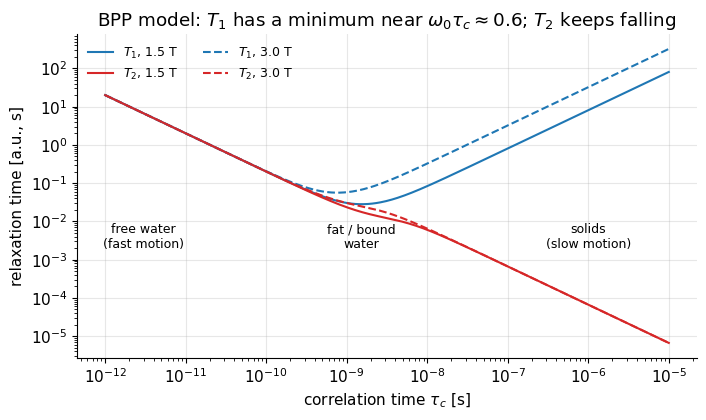

In [2]:
# BPP model: T1 and T2 versus correlation time tau_c (qualitative, arbitrary K)
tau_c = np.logspace(-12, -5, 400)            # correlation time [s]
K = 1e10                                     # coupling constant [s^-2], arbitrary scale

def J(w, tc):
    """spectral density of a single-exponential random motion"""
    return tc / (1 + (w * tc) ** 2)

fig, ax = plt.subplots(figsize=(8, 4.2))
for B0, ls in [(1.5, "-"), (3.0, "--")]:
    w0 = 2 * np.pi * mt.larmor_frequency(B0)  # Larmor angular frequency [rad/s]
    R1 = K * (J(w0, tau_c) + 4 * J(2 * w0, tau_c))
    R2 = K / 2 * (3 * J(0, tau_c) + 5 * J(w0, tau_c) + 2 * J(2 * w0, tau_c))
    ax.loglog(tau_c, 1 / R1, "C0" + ls, label=f"$T_1$, {B0} T")
    ax.loglog(tau_c, 1 / R2, "C3" + ls, label=f"$T_2$, {B0} T")
for x, txt in [(3e-12, "free water\n(fast motion)"), (1.5e-9, "fat / bound\nwater"), (1e-6, "solids\n(slow motion)")]:
    ax.annotate(txt, (x, 2e-3), ha="center", fontsize=9)
ax.set_xlabel(r"correlation time $\tau_c$ [s]")
ax.set_ylabel("relaxation time [a.u., s]")
ax.set_title("BPP model: $T_1$ has a minimum near $\\omega_0\\tau_c\\approx0.6$; $T_2$ keeps falling")
ax.legend(ncol=2, fontsize=9)
plt.show()

*Interpretation:* fluids sit on the left (long $T_1\approx T_2$), solids on the right (long $T_1$, tiny $T_2$), fat near the $T_1$ minimum; moving from 1.5 T to 3 T lengthens $T_1$ for everything right of the very-fast-motion regime.

### Typical $T_1$ and $T_2$ values

Literature values scatter by ±10–30 % depending on the measurement method, so treat these as typical, not exact.

#### 1.5 T

| Tissue | $T_1$ (ms) | $T_2$ (ms) |
|---|---|---|
| Brain white matter (WM) | 790 | 90 |
| Brain gray matter (GM) | 920 | 100 |
| Cerebrospinal fluid (CSF) | >4000 | ∼2000 |
| Blood (arterial) | 1200 | 50 |
| Liver parenchyma | 490 | 40 |
| Lung | 830 | 80 |
| Myocardium | 870 | 60 |
| Skeletal muscle | 870 | 50 |
| Lipids (fat) | 260 | 80 |

Source: Bernstein, King, Zhou, *Handbook of MRI Pulse Sequences* (Elsevier 2004).

#### 3 T

| Tissue | $T_1$ (ms) | $T_2$ (ms) | Remark |
|---|---|---|---|
| White matter | 800 | 110 | many studies report ≈ 1000–1100 / 70 ms (e.g. Stanisz et al. 2005) |
| Gray matter | 1300 | 80 | ≈ 1400–1800 / 100 ms in other studies; normally $T_2^{GM} > T_2^{WM}$ |
| CSF | 3700 | 1700 | |
| Muscle | 1000 | 30 | ≈ 1400 / 50 ms (Stanisz) |
| Fat | 400 | 100 | |
| Liver | 800 | 40 | |
| Cartilage | 1200 | 40 | |

Sources (original book): McRobbie et al., *MRI from Picture to Proton*; *MRI: The Basics*. Remark column added from Stanisz G.J. et al., "T1, T2 relaxation and magnetization transfer in tissue at 3T", *Magn. Reson. Med.* 54:507–512 (2005).

> **⚠️ Common confusion:** the original 3 T table lists WM $T_2$ (110 ms) longer than GM $T_2$ (80 ms). Most measurements find the opposite (GM ≈ 100 ms, WM ≈ 70 ms), which is why GM is *brighter* than WM on $T_2$-weighted brain images at every field strength. For the computations below we use the self-consistent set in the next code cell.

In [3]:
# Tissue parameters used in this notebook (all times in SECONDS, M0 relative to CSF = 1)
TISSUES = {
    1.5: {"WM": dict(M0=0.70, T1=0.79, T2=0.090),
          "GM": dict(M0=0.80, T1=0.92, T2=0.100),
          "CSF": dict(M0=1.00, T1=4.00, T2=2.000),
          "fat": dict(M0=0.90, T1=0.26, T2=0.080),
          "muscle": dict(M0=0.75, T1=0.87, T2=0.050)},
    3.0: {"WM": dict(M0=0.70, T1=1.08, T2=0.070),
          "GM": dict(M0=0.80, T1=1.82, T2=0.100),
          "CSF": dict(M0=1.00, T1=4.00, T2=1.800),
          "fat": dict(M0=0.90, T1=0.40, T2=0.100),
          "muscle": dict(M0=0.75, T1=1.41, T2=0.050)},
}
COLORS = {"WM": "C0", "GM": "C1", "CSF": "C2", "fat": "C3", "muscle": "C4"}
for B0, tab in TISSUES.items():
    print(f"B0 = {B0} T, f0 = {mt.larmor_frequency(B0)/1e6:.1f} MHz")
    for name, p in tab.items():
        print(f"   {name:7s} M0={p['M0']:.2f}  T1={p['T1']*1e3:6.0f} ms  T2={p['T2']*1e3:6.0f} ms")

B0 = 1.5 T, f0 = 63.9 MHz
   WM      M0=0.70  T1=   790 ms  T2=    90 ms
   GM      M0=0.80  T1=   920 ms  T2=   100 ms
   CSF     M0=1.00  T1=  4000 ms  T2=  2000 ms
   fat     M0=0.90  T1=   260 ms  T2=    80 ms
   muscle  M0=0.75  T1=   870 ms  T2=    50 ms
B0 = 3.0 T, f0 = 127.7 MHz
   WM      M0=0.70  T1=  1080 ms  T2=    70 ms
   GM      M0=0.80  T1=  1820 ms  T2=   100 ms
   CSF     M0=1.00  T1=  4000 ms  T2=  1800 ms
   fat     M0=0.90  T1=   400 ms  T2=   100 ms
   muscle  M0=0.75  T1=  1410 ms  T2=    50 ms


## 3. The two building blocks: relaxation and RF rotation

Everything in this chapter follows from two ingredients you met in [A2 Bloch Equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb).

**(a) Free relaxation between pulses.** Without RF, in the rotating frame and on resonance, the Bloch equation splits into two first-order linear ODEs:

$$\frac{dM_z}{dt} = -\frac{M_z - M_0}{T_1},\qquad \frac{dM_{xy}}{dt} = -\frac{M_{xy}}{T_2}.$$

*In words:* $M_z$ relaxes towards $M_0$ at a speed proportional to how far away it is; $M_{xy}$ decays towards zero the same way,
where $M_z$ is the longitudinal and $M_{xy}=M_x+iM_y$ the transverse magnetization, $M_0$ the equilibrium value, $T_1$, $T_2$ the time constants (s).

> **🔁 Refresher:** an ODE of the form $dy/dt=-(y-y_\infty)/T$ has the solution $y(t)=y_\infty+(y(0)-y_\infty)e^{-t/T}$: the distance to the final value shrinks by a factor $e^{-1}\approx0.37$ every $T$ seconds. Check by differentiating. See [RM1 ODEs for MRI](../refreshers/RM1_ODEs_for_MRI.ipynb).

Applying the refresher with $y_\infty=M_0$ and $y_\infty=0$:

$$M_z(t) = M_0 + \big(M_z(0)-M_0\big)\,e^{-t/T_1},\qquad M_{xy}(t) = M_{xy}(0)\,e^{-t/T_2}.$$

*In words:* longitudinal magnetization **recovers** exponentially from wherever it started towards $M_0$; transverse magnetization **decays** exponentially to zero. A useful rearrangement is $M_z(t) = M_z(0)\,e^{-t/T_1} + M_0\,(1-e^{-t/T_1})$: "what is left of the start value" plus "what has regrown".

**(b) An RF pulse is (almost) an instantaneous rotation.** RF pulses last 0.1–5 ms, usually much shorter than $T_1$ and $T_2$, so we treat them as instantaneous rotations by the flip angle $\theta$ about an axis in the $xy$-plane. If there is no transverse magnetization just before the pulse ($M_{xy}^-=0$) then

$$M_z^+ = M_z^-\cos\theta,\qquad |M_{xy}^+| = M_z^-\sin\theta .$$

*In words:* the pulse tilts the vector by $\theta$; the part left along $z$ is the cosine, the part tipped into the transverse plane (the part we can measure) is the sine,
where the superscripts $-$/$+$ mean "just before"/"just after" the pulse.

## 4. TE controls $T_2$ / $T_2^*$ weighting

After excitation, the transverse magnetization decays with $T_2$ (in a spin echo) or with the faster $T_2^*$ (in a gradient echo; the difference is explained in [D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb) and [D3](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb)). The **echo time** TE is the time from the centre of the excitation pulse to the moment the centre of k-space is acquired (which dominates the image contrast). Therefore

$$S_{GE} \propto M_0\, e^{-TE/T_2^*},\qquad S_{SE} \propto M_0\, e^{-TE/T_2}.$$

*In words:* the longer you wait before "taking the picture", the more the signal of short-$T_2$ tissues has faded relative to long-$T_2$ tissues,
where $S_{GE}$/$S_{SE}$ is the gradient-echo / spin-echo signal, TE the echo time (s), $T_2^*\le T_2$.

The plot below (ported from the original) shows $e^{-TE/T_2}$ for a range of $T_2$ values.

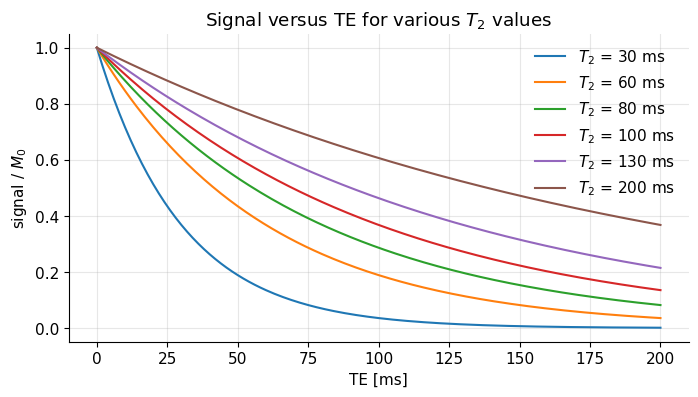

In [4]:
# TE contrast: signal versus TE for several T2 values (SI units, plotted in ms)
TE = np.linspace(0, 0.200, 201)                       # echo time [s]
T2_values = np.array([30, 60, 80, 100, 130, 200]) * 1e-3   # [s]

plt.figure()
for T2 in T2_values:
    plt.plot(TE * 1e3, np.exp(-TE / T2), label=f"$T_2$ = {T2*1e3:.0f} ms")
plt.xlabel("TE [ms]"); plt.ylabel(r"signal / $M_0$")
plt.title("Signal versus TE for various $T_2$ values")
plt.legend(); plt.show()

*Interpretation:* at TE ≈ 0 all curves start at 1 (no $T_2$ contrast); the spread between curves – i.e. the $T_2$ contrast – first grows with TE and later shrinks again as everything decays.

### Which TE gives the largest contrast?

For two tissues with equal $M_0$ (the general case is a short exercise), the contrast is $C(TE)=e^{-TE/T_{2A}}-e^{-TE/T_{2B}}$ with $T_{2A}>T_{2B}$. Setting the derivative to zero:

$$\frac{dC}{dTE} = -\frac{1}{T_{2A}}e^{-TE/T_{2A}}+\frac{1}{T_{2B}}e^{-TE/T_{2B}} = 0
\;\;\Rightarrow\;\; TE_{opt} = \frac{\ln(T_{2A}/T_{2B})}{1/T_{2B}-1/T_{2A}} .$$

*In words:* take logarithms of $e^{-TE/T_{2A}}/T_{2A}=e^{-TE/T_{2B}}/T_{2B}$ and solve the resulting linear equation for TE. The optimum TE always lies **between** the two $T_2$ values (it is their "logarithmic mean"), so a good rule of thumb is **TE ≈ $T_2$ of the tissues you want to separate**.

Example: WM ($T_2$ = 90 ms) vs GM (100 ms) at 1.5 T gives $TE_{opt}\approx 95$ ms – hence clinical $T_2$-weighted brain scans use TE ≈ 80–110 ms.

In [5]:
# Optimal TE for T2 contrast between two tissues (equal M0) - formula vs brute force
def te_opt(T2a, T2b):
    return np.log(T2a / T2b) / (1 / T2b - 1 / T2a)

T2a, T2b = 0.100, 0.090        # GM, WM at 1.5 T [s]
TE = np.linspace(0, 0.4, 4001)
C = np.exp(-TE / T2a) - np.exp(-TE / T2b)
print(f"formula: TE_opt = {te_opt(T2a, T2b)*1e3:.1f} ms;  brute force: {TE[np.argmax(C)]*1e3:.1f} ms")
print(f"CSF (2000 ms) vs GM (100 ms): TE_opt = {te_opt(2.0, 0.1)*1e3:.0f} ms")

formula: TE_opt = 94.8 ms;  brute force: 94.8 ms
CSF (2000 ms) vs GM (100 ms): TE_opt = 315 ms


*Interpretation:* formula and brute-force search agree; separating CSF from tissue would favour a very long TE (≈ 315 ms), but by then the tissue signal itself is almost gone – in practice SNR limits TE.

## 5. TR controls $T_1$ weighting – saturation recovery

We never measure $M_z$ directly. To make $T_1$ visible, we repeat the excitation every TR seconds so that $M_z$ does **not** fully recover between excitations; tissues with short $T_1$ recover more and give more signal at the next excitation.

All formulas in this section assume **perfect spoiling**: $M_{xy}=0$ just before every RF pulse. In practice this is done with an extra "spoiler" gradient at the end of each TR (gradient spoiling) and/or by changing the phase of the RF pulse from TR to TR (RF spoiling), or it is automatic when TR ≫ $T_2$. We test this assumption with a Bloch simulation in Section 7. See also [H2 Fast Imaging Pulse Sequences](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb).

### 5.1 90° pulses every TR (saturation recovery)

Step by step, with $M_z^-(n)$ / $M_z^+(n)$ the longitudinal magnetization just before/after pulse $n$:

1. Start in equilibrium: $M_z^-(0)=M_0$.
2. A 90° pulse puts everything into the transverse plane: $M_z^+(n)=M_z^-(n)\cos 90° = 0$, signal $\propto M_z^-(n)\sin 90° = M_z^-(n)$.
3. Recovery for TR (Section 3a with $M_z(0)=0$): $M_z^-(n+1) = M_0(1-e^{-TR/T_1})$.

So from the **second** excitation on, every pulse sees the same $M_z^-$; the signal is

$$S \propto M_0\,\big(1-e^{-TR/T_1}\big).$$

*In words:* the fraction of $M_0$ that has regrown after one TR,
where $TR$ is the repetition time and $T_1$ the longitudinal time constant. The first excitation is brighter ($M_0$); scanners discard it ("dummy scans").

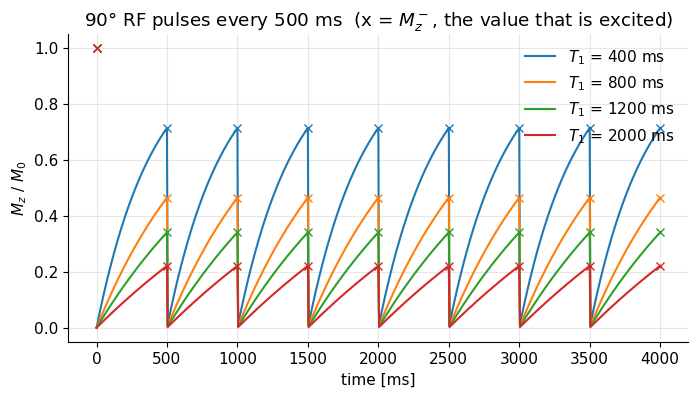

In [6]:
# Mz evolution between TRs with 90-degree pulses (ported from the original; SI units, plotted in ms)
def mz_train(T1, M0, flip_deg, TR, NTR, Nt_per_TR=100):
    """Return time axis, Mz(t) and the Mz just before/after each pulse for a train of
    perfectly spoiled pulses (instantaneous rotations)."""
    c = np.cos(np.deg2rad(flip_deg))
    t_rel = np.arange(1, Nt_per_TR + 1) * TR / Nt_per_TR    # times within one TR [s]
    Mz_minus = np.zeros((len(T1), NTR + 1)); Mz_plus = np.zeros((len(T1), NTR + 1))
    Mz_minus[:, 0] = M0
    Mz_plus[:, 0] = M0 * c
    t, Mz = [0.0], [Mz_plus[:, 0]]
    for n in range(NTR):
        for tt in t_rel:   # free relaxation (Section 3a)
            t.append(n * TR + tt)
            Mz.append(Mz_plus[:, n] * np.exp(-tt / T1) + M0 * (1 - np.exp(-tt / T1)))
        Mz_minus[:, n + 1] = Mz[-1]
        Mz_plus[:, n + 1] = Mz_minus[:, n + 1] * c       # RF pulse (spoiled: Mxy assumed 0)
    return np.array(t), np.array(Mz).T, Mz_minus, Mz_plus

T1s = np.array([0.4, 0.8, 1.2, 2.0]); M0s = np.ones(4)
TR, flip = 0.500, 90
t, Mz, Mzm, Mzp = mz_train(T1s, M0s, flip, TR, NTR=8)
plt.figure()
for i, T1 in enumerate(T1s):
    plt.plot(t * 1e3, Mz[i], color=f"C{i}", label=f"$T_1$ = {T1*1e3:.0f} ms")
    plt.plot(np.arange(9) * TR * 1e3, Mzm[i], "x", color=f"C{i}")
plt.xlabel("time [ms]"); plt.ylabel(r"$M_z$ / $M_0$")
plt.title(f"{flip}° RF pulses every {TR*1e3:.0f} ms  (x = $M_z^-$, the value that is excited)")
plt.legend(); plt.show()

*Interpretation:* after the first pulse every TR looks identical – steady state is reached in the second TR – and the short-$T_1$ tissue always has the most magnetization available when the next pulse arrives.

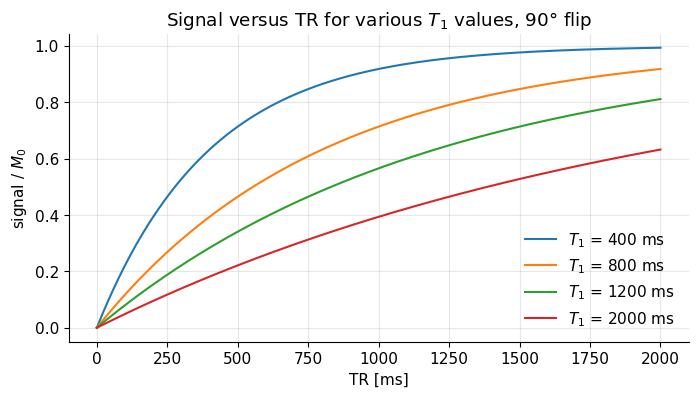

In [7]:
# Saturation recovery signal versus TR for several T1 values
TR = np.linspace(0, 2.0, 201)
plt.figure()
for T1 in T1s:
    plt.plot(TR * 1e3, 1 - np.exp(-TR / T1), label=f"$T_1$ = {T1*1e3:.0f} ms")
plt.xlabel("TR [ms]"); plt.ylabel(r"signal / $M_0$")
plt.title("Signal versus TR for various $T_1$ values, 90° flip")
plt.legend(); plt.show()

*Interpretation:* at very long TR all tissues have recovered fully (no $T_1$ contrast); at intermediate TR (a few hundred ms) the curves are well separated – that is the $T_1$-weighting regime.

### 5.2 The spin-echo signal equation

A spin echo (see [D3](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb)) adds a 180° refocusing pulse at TE/2. The commonly used formula is

$$S_{SE} = M_0\,\big(1-e^{-TR/T_1}\big)\,e^{-TE/T_2}\qquad(TE\ll TR).$$

*In words:* saturation recovery (the $T_1$ factor, set by TR) times transverse decay (the $T_2$ factor, set by TE). This is `mt.spin_echo_signal(TE, TR, T1, T2, M0)`.

<details><summary><b>📐 Derivation (optional): the exact spin-echo $T_1$ factor</b></summary>

The 180° pulse also hits the longitudinal magnetization that has started to regrow since the 90°. Track $M_z$ through one TR in steady state (perfect spoiling, so the 90° always leaves $M_z^+=0$):

1. After the 90° at $t=0$: $M_z = 0$.
2. At $t=TE/2$ (just before the 180°): $M_z = M_0(1-e^{-TE/(2T_1)})$.
3. The 180° inverts it: $M_z = -M_0(1-e^{-TE/(2T_1)})$.
4. Relaxation for the remaining $TR-TE/2$:
$$M_z^-=M_0+\big(-M_0(1-e^{-TE/2T_1})-M_0\big)e^{-(TR-TE/2)/T_1}
= M_0\Big[1-2e^{-(TR-TE/2)/T_1}+e^{-TR/T_1}\Big].$$

So the exact signal is $S_{SE}=M_0\big[1-2e^{-(TR-TE/2)/T_1}+e^{-TR/T_1}\big]e^{-TE/T_2}$. For $TE\to0$ the bracket becomes $1-2E_1+E_1=1-E_1$, the simple formula. The next code cell shows the difference is negligible for clinical parameters.

</details>

In [8]:
# Exact spin-echo T1 factor vs the TE << TR approximation
def se_exact(TE, TR, T1, T2, M0=1.0):
    return M0 * (1 - 2 * np.exp(-(TR - TE / 2) / T1) + np.exp(-TR / T1)) * np.exp(-TE / T2)

for TE, TR in [(0.015, 0.5), (0.100, 3.0), (0.100, 0.5)]:
    p = TISSUES[1.5]["GM"]
    a = mt.spin_echo_signal(TE, TR, p["T1"], p["T2"], p["M0"]); b = se_exact(TE, TR, p["T1"], p["T2"], p["M0"])
    print(f"GM, TE={TE*1e3:5.0f} ms TR={TR*1e3:5.0f} ms: simple {a:.4f}  exact {b:.4f}  rel. diff {abs(a-b)/b*100:.2f} %")

GM, TE=   15 ms TR=  500 ms: simple 0.2887  exact 0.2822  rel. diff 2.32 %
GM, TE=  100 ms TR= 3000 ms: simple 0.2830  exact 0.2818  rel. diff 0.45 %
GM, TE=  100 ms TR=  500 ms: simple 0.1234  exact 0.1043  rel. diff 18.30 %


*Interpretation:* the approximation is good to ~2 % for $T_1$-weighted settings and <1 % at long TR; it only fails when TE is a sizeable fraction of TR (last line), a combination that is not used anyway.

## 6. Small flip angles: the spoiled gradient-echo steady state

For $T_1$-weighting it is usually more efficient (more signal per unit time) to use flip angles **below 90°** and much shorter TRs (5–20 ms). Such sequences are called **spoiled gradient echo** (vendor names: FLASH – Siemens, SPGR – GE, T1-FFE – Philips). The steady-state signal is

$$S_{SPGR} = M_0\,\sin\theta\;\frac{1-E_1}{1-E_1\cos\theta}\;e^{-TE/T_2^*},\qquad E_1=e^{-TR/T_1}.$$

*In words:* the magnetization available along $z$ in steady state, $M_0(1-E_1)/(1-E_1\cos\theta)$, times the fraction $\sin\theta$ that the pulse tips into the transverse plane, times $T_2^*$ decay until TE,
where $\theta$ is the flip angle, $TR$ the repetition time and $E_1=e^{-TR/T_1}$. This is `mt.spoiled_gre_signal(flip, TE, TR, T1, T2star, M0)`.

<details><summary><b>📐 Derivation (optional): the one-equation fixed point</b></summary>

**Assumption ("perfect spoiling").** Just before every pulse, $M_{xy}^-=0$. Then only $M_z$ needs to be tracked and every pulse acts as $M_z^+=M_z^-\cos\theta$.

**One TR as a map.** Pulse, then relaxation for TR (Section 3a):
$$M_z^-(n+1) = \underbrace{M_z^-(n)\cos\theta}_{M_z^+(n)}\,E_1 + M_0(1-E_1).$$
This is a linear recursion $x_{n+1}=a\,x_n+b$ with $a=E_1\cos\theta$ and $b=M_0(1-E_1)$.

**Steady state = fixed point.** "Steady state" means $M_z^-$ is the same before every pulse: $x_{n+1}=x_n=M_{z,ss}$. Insert:
$$M_{z,ss}=M_{z,ss}\,E_1\cos\theta+M_0(1-E_1)\;\Rightarrow\;M_{z,ss}=\frac{M_0(1-E_1)}{1-E_1\cos\theta}.$$
The signal right after the pulse is $M_{z,ss}\sin\theta$; multiplying by $e^{-TE/T_2^*}$ gives the formula above.

**How fast is steady state reached?** Subtract the fixed-point equation from the recursion: $x_{n+1}-M_{z,ss}=a\,(x_n-M_{z,ss})$. The deviation shrinks by the factor $a=E_1\cos\theta<1$ every TR, so after $n$ pulses it is $a^n$ times the initial deviation. To get within 1 %: $n\approx\ln(0.01)/\ln(E_1\cos\theta)$. For 90° ($a=0$) one pulse suffices – consistent with Section 5.1. For $\theta=15°$, TR = 10 ms, $T_1$ = 1 s we get $a\approx0.956$ and $n\approx 100$ pulses (1 s)!

**Check:** $\theta=90°$ gives $\cos\theta=0$, $\sin\theta=1$ and $S=M_0(1-E_1)$, the saturation-recovery result.

</details>

> **🧭 Intuition:** a small flip angle "spends" only a little of $M_z$ each TR, so $M_z$ stays high; a 90° pulse spends everything, and with short TR there is almost nothing to spend next time. The Ernst angle (below) is the best compromise between "tip more" (bigger $\sin\theta$) and "keep more" (bigger $M_{z,ss}$).

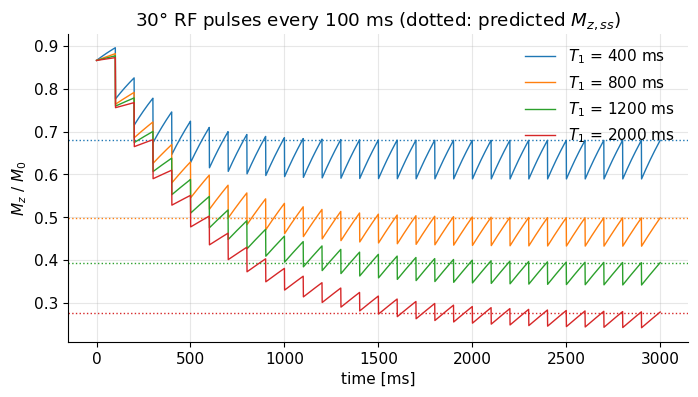

In [9]:
# Mz evolution with < 90-degree pulses (ported from the original): many TRs to reach steady state
TR, flip = 0.100, 30
t, Mz, Mzm, Mzp = mz_train(T1s, M0s, flip, TR, NTR=30)
plt.figure()
for i, T1 in enumerate(T1s):
    plt.plot(t * 1e3, Mz[i], color=f"C{i}", lw=1, label=f"$T_1$ = {T1*1e3:.0f} ms")
    E1 = np.exp(-TR / T1); c = np.cos(np.deg2rad(flip))
    plt.axhline((1 - E1) / (1 - E1 * c), color=f"C{i}", ls=":", lw=1)   # predicted Mz,ss
plt.xlabel("time [ms]"); plt.ylabel(r"$M_z$ / $M_0$")
plt.title(f"{flip}° RF pulses every {TR*1e3:.0f} ms (dotted: predicted $M_{{z,ss}}$)")
plt.legend(); plt.show()

*Interpretation:* the saw-tooth envelope converges geometrically onto the dotted fixed-point values; long-$T_1$ tissues take longer (their $E_1\cos\theta$ is closer to 1).

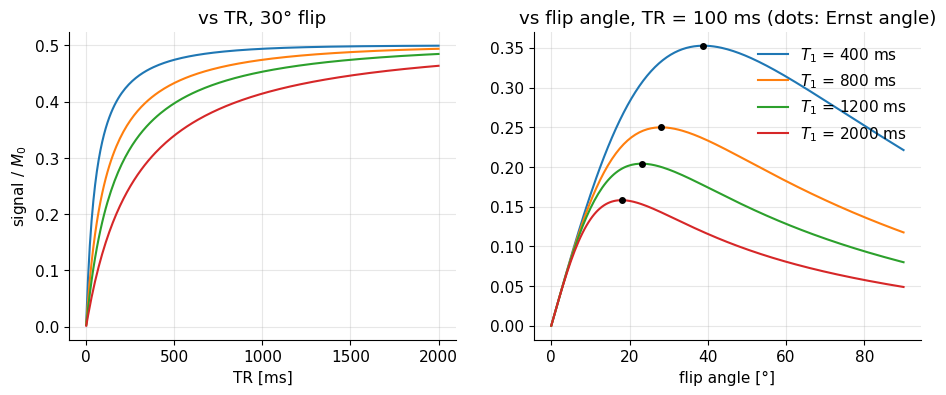

In [10]:
# Spoiled GRE signal versus TR (30 deg) and versus flip angle (TR = 100 ms), ported from the original
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
TR = np.linspace(1e-3, 2.0, 200)
for T1 in T1s:
    axs[0].plot(TR * 1e3, mt.spoiled_gre_signal(np.deg2rad(30), 0, TR, T1, 1.0), label=f"{T1*1e3:.0f} ms")
axs[0].set_xlabel("TR [ms]"); axs[0].set_ylabel(r"signal / $M_0$"); axs[0].set_title("vs TR, 30° flip")
flips = np.linspace(0, 90, 181)
TR = 0.100
for T1 in T1s:
    s = mt.spoiled_gre_signal(np.deg2rad(flips), 0, TR, T1, 1.0)
    axs[1].plot(flips, s, label=f"$T_1$ = {T1*1e3:.0f} ms")
    thE = np.rad2deg(mt.ernst_angle(TR, T1))
    axs[1].plot(thE, mt.spoiled_gre_signal(np.deg2rad(thE), 0, TR, T1, 1.0), "k.", ms=8)
axs[1].set_xlabel("flip angle [°]"); axs[1].set_title(f"vs flip angle, TR = {TR*1e3:.0f} ms (dots: Ernst angle)")
axs[1].legend(); plt.show()

*Interpretation:* each tissue has its own flip angle of maximum signal (black dots); longer $T_1$ → smaller optimal angle.

### The Ernst angle

Which flip angle maximizes $S_{SPGR}$ for a given TR and $T_1$? Only the factor $g(\theta)=\sin\theta/(1-E_1\cos\theta)$ depends on $\theta$. By the quotient rule,

$$\frac{dg}{d\theta}=\frac{\cos\theta\,(1-E_1\cos\theta)-\sin\theta\,(E_1\sin\theta)}{(1-E_1\cos\theta)^2}
=\frac{\cos\theta-E_1(\cos^2\theta+\sin^2\theta)}{(1-E_1\cos\theta)^2}=\frac{\cos\theta-E_1}{(1-E_1\cos\theta)^2}.$$

*In words:* the derivative is zero exactly when $\cos\theta=E_1$ (it is positive for smaller and negative for larger angles, so this is a maximum). Hence the **Ernst angle**

$$\theta_E=\arccos\!\big(e^{-TR/T_1}\big)\;\approx\;\sqrt{2\,TR/T_1}\quad (TR\ll T_1).$$

*In words:* the optimal flip angle depends only on the ratio TR/$T_1$; the approximation follows from $\cos\theta\approx1-\theta^2/2$ and $e^{-x}\approx1-x$,
where $\theta_E$ is in radians. Example: TR = 10 ms, $T_1$ = 1 s → $\theta_E\approx\sqrt{0.02}=0.14$ rad ≈ 8.1°.

Inserting $\cos\theta_E=E_1$, $\sin\theta_E=\sqrt{1-E_1^2}$ gives the maximum signal

$$S_{max}=M_0\frac{(1-E_1)\sqrt{1-E_1^2}}{1-E_1^2}=M_0\sqrt{\frac{1-E_1}{1+E_1}}\;\approx\;M_0\sqrt{\frac{TR}{2T_1}}.$$

*In words:* at the Ernst angle the signal grows like $\sqrt{TR}$. Since the number of TRs per second grows like $1/TR$ and noise averages like $\sqrt{\cdot}$, signal per $\sqrt{\text{time}}$ is roughly independent of TR – which is why very short TR with small flips is so efficient.

> **⚠️ Common confusion:** the Ernst angle maximizes the **signal of one tissue**, not the **contrast** between two tissues. For $T_1$-weighted contrast you typically choose a flip angle 1.5–3× larger than the Ernst angle (see the next cell).

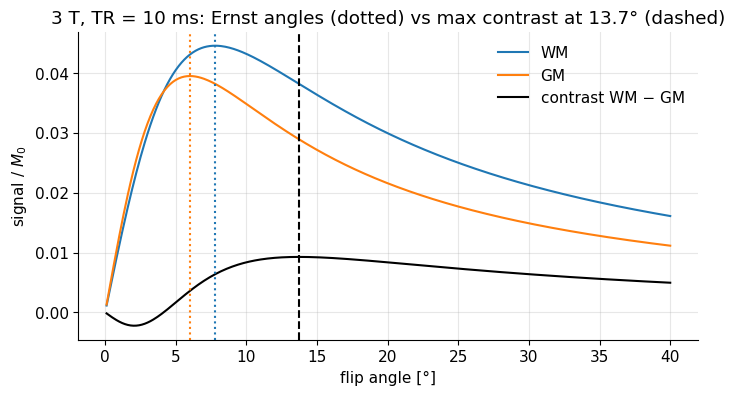

Ernst angle WM: 7.8°, GM: 6.0°, max-contrast angle: 13.7°


In [11]:
# Ernst angle (max signal) vs angle of max WM/GM contrast for a 3D T1-weighted spoiled GRE at 3 T
TR = 0.010                                  # 10 ms
flips = np.deg2rad(np.linspace(0.1, 40, 400))
wm, gm = TISSUES[3.0]["WM"], TISSUES[3.0]["GM"]
S_wm = mt.spoiled_gre_signal(flips, 0.003, TR, wm["T1"], 0.045, wm["M0"])   # T2* ~ 45 ms (assumed)
S_gm = mt.spoiled_gre_signal(flips, 0.003, TR, gm["T1"], 0.050, gm["M0"])
plt.figure()
plt.plot(np.rad2deg(flips), S_wm, label="WM"); plt.plot(np.rad2deg(flips), S_gm, label="GM")
plt.plot(np.rad2deg(flips), S_wm - S_gm, "k", label="contrast WM − GM")
for name, p in [("WM", wm), ("GM", gm)]:
    plt.axvline(np.rad2deg(mt.ernst_angle(TR, p["T1"])), color=COLORS[name], ls=":")
best = np.rad2deg(flips[np.argmax(S_wm - S_gm)])
plt.axvline(best, color="k", ls="--")
plt.xlabel("flip angle [°]"); plt.ylabel(r"signal / $M_0$"); plt.legend()
plt.title(f"3 T, TR = 10 ms: Ernst angles (dotted) vs max contrast at {best:.1f}° (dashed)")
plt.show()
print("Ernst angle WM: %.1f°, GM: %.1f°, max-contrast angle: %.1f°" %
      (np.rad2deg(mt.ernst_angle(TR, wm["T1"])), np.rad2deg(mt.ernst_angle(TR, gm["T1"])), best))

*Interpretation:* the signals peak near 6–8° but the WM–GM difference peaks at roughly twice that angle; typical 3D $T_1$-weighted GRE protocols indeed use 10–20°.

## 7. Bloch simulation: does the formula really hold? (What spoiling assumes)

The fixed-point derivation assumed $M_{xy}=0$ before every pulse. Here we check that with a full Bloch simulation (`mt.bloch_simulate`) of a **voxel** containing 200 isochromats (groups of spins with the same frequency). Three variants:

1. **Ideal spoiling** – we set $M_{xy}=0$ by hand before every pulse (what the formula assumes).
2. **Gradient spoiling only** – a spoiler gradient at the end of each TR spreads the isochromat phases uniformly over one full cycle (2π) across the voxel; modelled as off-resonance $\Delta f_j=j/(N\,TR)$, $j=0\dots N-1$. Nothing is zeroed by hand.
3. **Gradient + RF spoiling** – additionally the RF phase follows $\phi_n=\phi_0\,n(n+1)/2$ with $\phi_0=117°$ (the receiver is demodulated with the same phase). This quadratic phase schedule (Zur et al. 1991) makes the echoes from older pulses add with pseudo-random phases.

The voxel signal is the average of $M_{xy}$ over all isochromats right after each pulse (TE ≈ 0).

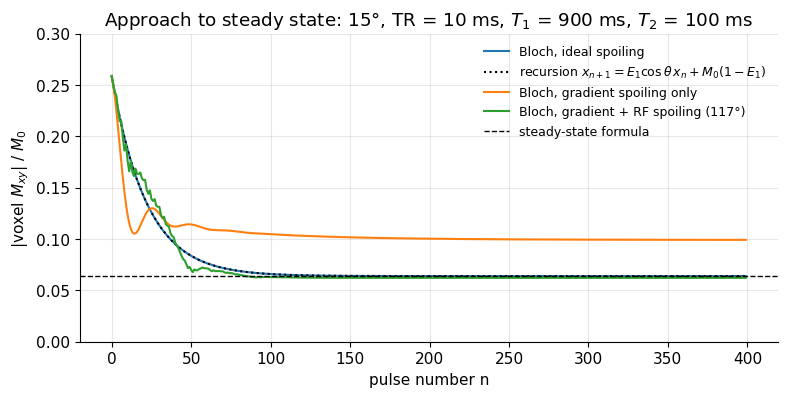

ideal    : steady state 0.0639   (formula 0.0639, deviation -0.0 %)
gradient : steady state 0.0992   (formula 0.0639, deviation +55.2 %)
rf       : steady state 0.0622   (formula 0.0639, deviation -2.7 %)


In [12]:
# Bloch simulation of a spoiled gradient-echo train for one voxel (200 isochromats)
T1, T2 = 0.9, 0.10            # [s] (GM-like at 1.5 T)
TR, flip = 0.010, np.deg2rad(15)
Ns, NTR, trf = 200, 400, 10e-6                    # isochromats, pulses, hard-pulse duration [s]
df_spoil = (np.arange(Ns) / Ns) / TR              # [Hz] -> phases spread over 2*pi in one TR

def spgr_bloch(mode, phi0=np.deg2rad(117)):
    """Return |voxel Mxy| right after each pulse for mode in {'ideal','gradient','rf'}."""
    M = np.tile([0.0, 0.0, 1.0], (Ns, 1))
    sig = np.zeros(NTR)
    for n in range(NTR):
        if mode == "ideal":
            M[:, :2] = 0.0                              # perfect spoiling by hand
        phase = phi0 * n * (n + 1) / 2 if mode == "rf" else 0.0
        b1 = mt.b1_for_flip(flip, trf) * np.exp(1j * phase)   # hard pulse with RF phase
        _, M = mt.bloch_simulate(B1=np.array([b1]), dt=trf, M_init=M, T1=T1, T2=T2,
                                 df=df_spoil, return_all=False)
        sig[n] = np.abs(np.mean(M[:, 0] + 1j * M[:, 1]) * np.exp(-1j * phase))
        # free precession + relaxation for the rest of the TR (one exact step)
        _, M = mt.bloch_simulate(n_steps=1, dt=TR - trf, M_init=M, T1=T1, T2=T2,
                                 df=0.0 if mode == "ideal" else df_spoil, return_all=False)
    return sig

results = {m: spgr_bloch(m) for m in ["ideal", "gradient", "rf"]}
S_formula = mt.spoiled_gre_signal(flip, 0.0, TR, T1, 1.0)

# recursion from the derivation (Mz only) for comparison
x, rec = 1.0, []
for n in range(NTR):
    rec.append(x * np.sin(flip)); x = x * np.cos(flip) * np.exp(-TR / T1) + (1 - np.exp(-TR / T1))

plt.figure(figsize=(9, 4))
n = np.arange(NTR)
plt.plot(n, results["ideal"], label="Bloch, ideal spoiling")
plt.plot(n, rec, "k:", label="recursion $x_{n+1}=E_1\\cos\\theta\\,x_n+M_0(1-E_1)$")
plt.plot(n, results["gradient"], label="Bloch, gradient spoiling only")
plt.plot(n, results["rf"], label="Bloch, gradient + RF spoiling (117°)")
plt.axhline(S_formula, color="k", ls="--", lw=1, label="steady-state formula")
plt.xlabel("pulse number n"); plt.ylabel(r"|voxel $M_{xy}$| / $M_0$")
plt.ylim(0, 0.3); plt.legend(fontsize=9)
plt.title("Approach to steady state: 15°, TR = 10 ms, $T_1$ = 900 ms, $T_2$ = 100 ms")
plt.show()
for m, s in results.items():
    print(f"{m:9s}: steady state {s[-20:].mean():.4f}   (formula {S_formula:.4f}, "
          f"deviation {100*(s[-20:].mean()/S_formula-1):+.1f} %)")

*Interpretation:* with ideal spoiling the Bloch simulation lands exactly on the formula (and on the recursion); gradient spoiling alone leaves a clearly **too high** and $T_2$-dependent signal, because transverse magnetization from earlier pulses is partly rotated back and forms echoes; adding RF spoiling brings the signal to within a few percent of the ideal value.

> **🔧 Engineering reality:** spoiler gradients cost time (TR) and gradient heating; RF spoiling costs nothing but needs a phase-coherent RF chain whose phase can be switched every TR (standard on all modern scanners). If you remove spoiling entirely and balance all gradients, the leftover transverse magnetization is *kept on purpose*: that is **balanced SSFP** (TrueFISP/FIESTA/bFFE), with signal `mt.bssfp_signal` and $T_2/T_1$ contrast – see [H2 Fast Imaging Pulse Sequences](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb).

## 8. $T_1$, $T_2$ and proton-density weighting

By choosing TE, TR (and flip angle) we make one factor of the signal equation dominate the differences between tissues. "**X-weighted**" means: *the contrast is mainly, but never exclusively, caused by differences in X.*

|  | **Short TE** ($TE\ll T_2$, e.g. 10–20 ms SE) | **Long TE** ($TE\sim T_2$, e.g. 80–120 ms SE) |
|---|---|---|
| **Short TR** ($TR\lesssim T_1$, e.g. 400–600 ms SE at 1.5 T) | $T_1$-weighted | not used (low signal, mixed contrast that cancels) |
| **Long TR** ($TR\gtrsim 3T_1$ of tissue, e.g. 2500–6000 ms) | PD-weighted | $T_2$ / $T_2^*$-weighted |

Precise definitions (spin echo, $S = M_0(1-e^{-TR/T_1})e^{-TE/T_2}$):

* **$T_1$-weighted:** TR comparable to tissue $T_1$ (so the $T_1$ factor differs between tissues) and TE ≪ $T_2$ (so $e^{-TE/T_2}\approx1$ for all). **Short-$T_1$ tissues are bright** (fat, WM brighter than GM, contrast agent), long-$T_1$ fluid is dark.
* **$T_2$-weighted:** TR ≫ $T_1$ (so $1-e^{-TR/T_1}\approx1$ for all tissue; CSF may still be partly saturated) and TE ≈ $T_2$. **Long-$T_2$ tissues are bright** (fluid, edema; GM brighter than WM).
* **PD-weighted:** TR ≫ $T_1$ and TE ≪ $T_2$: both relaxation factors ≈ 1, so $S\approx M_0$. **High proton density is bright**; contrast is low because $M_0$ varies only by ~±20 % between soft tissues.
* For gradient echoes the same table holds with $T_2^*$ instead of $T_2$, and with "short TR" meaning a few ms combined with a moderate flip angle (Section 6). **Very small flip angles** ($\theta\ll\theta_E$) remove $T_1$ weighting even at short TR, giving PD weighting (see below).

The next cell plots the signal versus TR (short TE = 15 ms) and versus TE (long TR = 4000 ms) for WM, GM, CSF and fat at 1.5 T and 3 T.

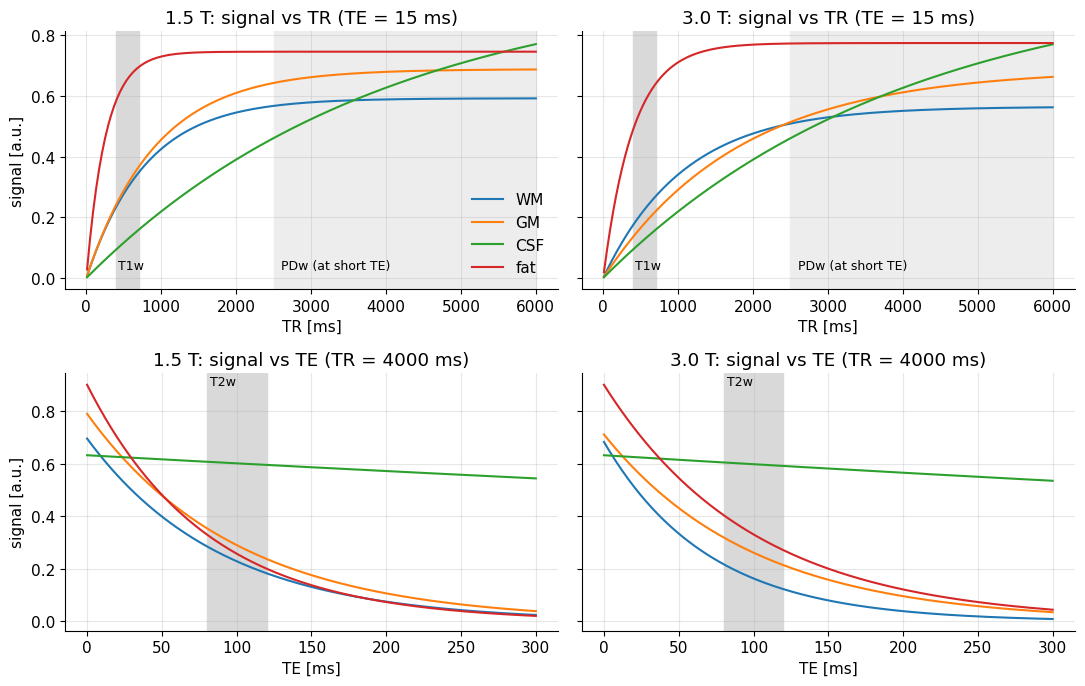

In [13]:
# Spin-echo signal vs TR (short TE) and vs TE (long TR) for brain tissues + fat at 1.5 T and 3 T
fig, axs = plt.subplots(2, 2, figsize=(11, 7), sharey="row")
TR = np.linspace(0.01, 6.0, 300); TE = np.linspace(0, 0.3, 300)
for col, B0 in enumerate([1.5, 3.0]):
    for name in ["WM", "GM", "CSF", "fat"]:
        p = TISSUES[B0][name]
        axs[0, col].plot(TR * 1e3, mt.spin_echo_signal(0.015, TR, p["T1"], p["T2"], p["M0"]),
                         color=COLORS[name], label=name)
        axs[1, col].plot(TE * 1e3, mt.spin_echo_signal(TE, 4.0, p["T1"], p["T2"], p["M0"]),
                         color=COLORS[name], label=name)
    axs[0, col].axvspan(400, 700, color="0.85", zorder=0); axs[0, col].text(420, 0.03, "T1w", fontsize=9)
    axs[0, col].axvspan(2500, 6000, color="0.93", zorder=0); axs[0, col].text(2600, 0.03, "PDw (at short TE)", fontsize=9)
    axs[1, col].axvspan(80, 120, color="0.85", zorder=0); axs[1, col].text(82, 0.9, "T2w", fontsize=9)
    axs[0, col].set_title(f"{B0} T: signal vs TR (TE = 15 ms)"); axs[0, col].set_xlabel("TR [ms]")
    axs[1, col].set_title(f"{B0} T: signal vs TE (TR = 4000 ms)"); axs[1, col].set_xlabel("TE [ms]")
axs[0, 0].set_ylabel("signal [a.u.]"); axs[1, 0].set_ylabel("signal [a.u.]"); axs[0, 0].legend()
plt.tight_layout(); plt.show()

*Interpretation:* in the grey T1w band the order is fat > WM > GM > CSF; at long TR and short TE the order follows $M_0$ (CSF > fat > GM > WM, but differences are small); along TE the long-$T_2$ CSF stays bright while tissues fade (T2w: CSF > GM > WM). At 3 T the longer $T_1$ values shift the $T_1$-weighting band to longer TR.

> **⚠️ Common confusion:** contrast can **reverse**. GM is darker than WM on $T_1$-weighted but brighter on $T_2$-weighted images; somewhere in between, the two effects cancel and WM/GM contrast vanishes. The map below shows where.

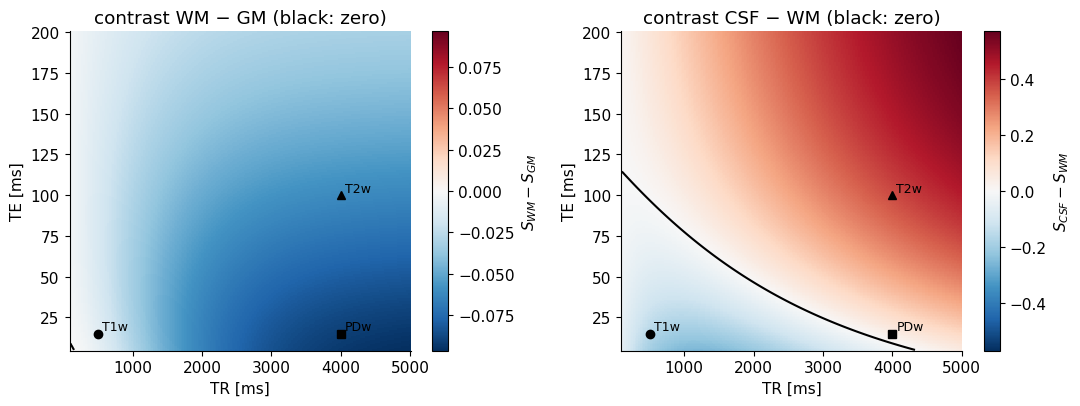

In [14]:
# Map of WM-GM and CSF-WM contrast over the (TR, TE) plane at 1.5 T (spin echo)
TRg, TEg = np.meshgrid(np.linspace(0.1, 5.0, 200), np.linspace(0.005, 0.2, 200))
def S(name, B0=1.5):
    p = TISSUES[B0][name]; return mt.spin_echo_signal(TEg, TRg, p["T1"], p["T2"], p["M0"])
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (a, b) in zip(axs, [("WM", "GM"), ("CSF", "WM")]):
    C = S(a) - S(b); v = np.abs(C).max()
    im = ax.pcolormesh(TRg * 1e3, TEg * 1e3, C, cmap="RdBu_r", vmin=-v, vmax=v, shading="auto")
    ax.contour(TRg * 1e3, TEg * 1e3, C, [0], colors="k", linewidths=1.5)
    plt.colorbar(im, ax=ax, label=f"$S_{{{a}}}-S_{{{b}}}$")
    ax.set_xlabel("TR [ms]"); ax.set_ylabel("TE [ms]"); ax.set_title(f"contrast {a} − {b} (black: zero)")
    ax.grid(False)
for ax in axs:
    ax.plot(500, 15, "ko"); ax.text(560, 17, "T1w", fontsize=9)
    ax.plot(4000, 15, "ks"); ax.text(4060, 17, "PDw", fontsize=9)
    ax.plot(4000, 100, "k^"); ax.text(4060, 102, "T2w", fontsize=9)
plt.tight_layout(); plt.show()

*Interpretation:* red means the first tissue is brighter. WM–GM contrast flips sign along the black line, so a careless "intermediate" choice of TR/TE can make the brain featureless; CSF–WM is negative (CSF dark) at short TR/short TE and strongly positive at long TE.

### Text from the original, rewritten

**$T_2$- and $T_2^*$-weighting.** Choose TE long enough that tissues with different $T_2$ have clearly different amounts of transverse magnetization left. For example, at TE = 80–100 ms we see good contrast between white matter ($T_2\approx$ 70–90 ms), gray matter ($\approx$ 100 ms) and CSF ($\approx$ 2000 ms). TR is chosen long relative to tissue $T_1$ values, so that $M_z$ recovers almost fully every repetition and $T_1$-weighting is removed. Longer-$T_2$ tissues are brighter. Whether the weighting is $T_2$ or $T_2^*$ depends on the sequence: spin echoes give $T_2$, gradient echoes $T_2^*$ ([D3](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb)).

**$T_1$-weighting.** Choose TR short enough that $M_z$ recovers incompletely. With TR = 500 ms and 90° pulses there is good contrast between fat ($T_1\approx$ 260–400 ms) and muscle ($T_1\approx$ 900–1400 ms). With a gradient echo we can use smaller flip angles and much shorter TR (e.g. 30° and TR = 100–200 ms, or 15° and 10 ms) and get the same kind of contrast with more signal per unit time. TE is chosen short relative to $T_2$ to suppress $T_2$-weighting. Shorter-$T_1$ tissues are brighter.

**PD-weighting.** Short TE (removes $T_2$ weighting) and long TR (removes $T_1$ weighting) leave a contrast determined by the proton density, i.e. by $M_0$. Higher-PD tissues are brighter. PD-weighting is also possible at **short TR with very small flip angles**: if $\theta\ll\theta_E$ then $\theta^2E_1/2\ll 1-E_1$ and

$$S_{SPGR}\approx M_0\,\theta\,\frac{1-E_1}{1-E_1+\theta^2E_1/2}\approx M_0\,\theta\qquad(\theta\ll\theta_E).$$

*In words:* using $\sin\theta\approx\theta$ and $\cos\theta\approx1-\theta^2/2$, the $T_1$ dependence drops out when the flip angle is much smaller than the Ernst angle, so every tissue gives signal ≈ $M_0\theta$. The next cell (ported from the original) zooms in on small flip angles.

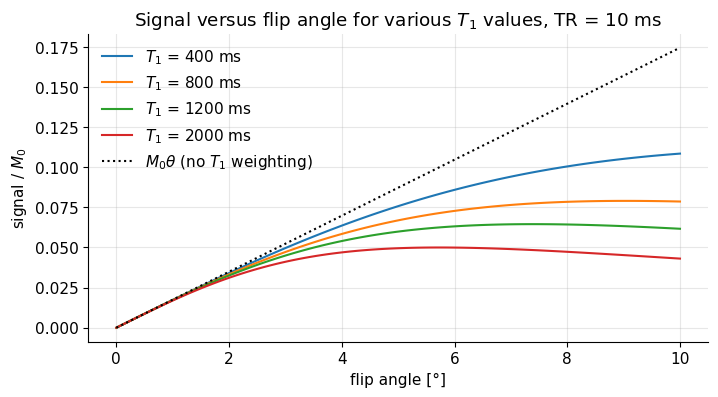

In [15]:
# PD weighting with small flip angles: TR = 10 ms, zoom on 0-10 degrees
TR = 0.010
flips = np.linspace(0, 10, 100)
plt.figure()
for T1 in T1s:
    plt.plot(flips, mt.spoiled_gre_signal(np.deg2rad(flips), 0, TR, T1, 1.0), label=f"$T_1$ = {T1*1e3:.0f} ms")
plt.plot(flips, np.deg2rad(flips), "k:", label=r"$M_0\theta$ (no $T_1$ weighting)")
plt.xlabel("flip angle [°]"); plt.ylabel(r"signal / $M_0$"); plt.legend()
plt.title(f"Signal versus flip angle for various $T_1$ values, TR = {TR*1e3:.0f} ms")
plt.show()

*Interpretation:* below ~2° all curves lie on the $M_0\theta$ line – the $T_1$ contrast is gone (at the price of a small signal).

## 9. Inversion recovery

**Inversion recovery (IR)** creates (or removes!) $T_1$ contrast with a **180° inversion pulse**, followed after the **inversion time TI** by the normal excitation (90°) and readout. During TI the inverted magnetization $-M_0$ recovers through zero towards $+M_0$; tissues with different $T_1$ cross zero at different times.

The most important clinical use is to **null** (make black) one tissue:

* **STIR** (short-tau inversion recovery) nulls **fat** with a short TI;
* **FLAIR** (fluid-attenuated inversion recovery) nulls **CSF** with a long TI, giving $T_2$-weighted images in which lesions near the ventricles are no longer hidden by bright CSF.

The signal is

$$S_{IR} = M_0\big(1-2e^{-TI/T_1}+e^{-TR/T_1}\big)\,e^{-TE/T_2}.$$

*In words:* recovery from the inverted state (the $-2e^{-TI/T_1}$ term) corrected for the incomplete recovery before the inversion (the $+e^{-TR/T_1}$ term), times $T_2$ decay. The bracket can be **negative**: $M_z$ is still pointing down when it is excited. This is `mt.inversion_recovery_signal(TI, TR, TE, T1, T2, M0)`.

<details><summary><b>📐 Derivation (optional): IR signal including the TR term</b></summary>

One repetition: 180° at $t=0$, 90° at $t=TI$, next 180° at $t=TR$. Assume perfect spoiling and that the readout is short (TE ≪ TR, so we ignore what the readout's own refocusing pulse does to $M_z$).

1. Just after the 90° at TI: $M_z=0$ (the 90° tips everything into the transverse plane).
2. Recovery for $TR-TI$ until the next inversion: $M_z = M_0\big(1-e^{-(TR-TI)/T_1}\big)$.
3. The 180° inverts this: $M_z^+ = -M_0\big(1-e^{-(TR-TI)/T_1}\big)$.
4. Recovery for TI, with start value $M_z^+$:
$$M_z(TI)=M_0+\big(M_z^+-M_0\big)e^{-TI/T_1}
=M_0-M_0\big(2-e^{-(TR-TI)/T_1}\big)e^{-TI/T_1}
=M_0\big(1-2e^{-TI/T_1}+e^{-TR/T_1}\big).$$
5. The 90° converts $M_z(TI)$ into transverse magnetization, which then decays with $T_2$ until TE.

Because step 1 resets $M_z$ to zero regardless of history, the steady state is reached from the **second** repetition on (just like 90° saturation recovery). If the excitation flip angle is $<90°$ (e.g. MPRAGE) step 1 no longer resets the history, and the formula changes.

**Null point.** Setting the bracket to zero: $e^{-TI/T_1}=\tfrac12(1+e^{-TR/T_1})$, so
$$TI_{null}=T_1\ln\frac{2}{1+e^{-TR/T_1}}\;\xrightarrow{\;TR\gg T_1\;}\;T_1\ln 2\approx0.693\,T_1 .$$

</details>

**Null point:** $\;TI_{null}=T_1\ln\dfrac{2}{1+e^{-TR/T_1}}\approx T_1\ln2$ for $TR\gg T_1$.

*In words:* the magnetization of a tissue crosses zero after about 69 % of its $T_1$; with finite TR the tissue was not fully recovered before the inversion, so it starts less negative and crosses zero earlier,
where $T_1$ is the $T_1$ of the tissue to be nulled.

In [16]:
# Null-point inversion times for STIR (fat) and FLAIR (CSF)
def ti_null(T1, TR=np.inf):
    return T1 * np.log(2 / (1 + np.exp(-TR / T1)))

for B0 in [1.5, 3.0]:
    fat, csf = TISSUES[B0]["fat"]["T1"], TISSUES[B0]["CSF"]["T1"]
    print(f"{B0} T: STIR  (fat, T1={fat*1e3:.0f} ms): TI_null = {ti_null(fat, 3.0)*1e3:5.0f} ms (TR=3 s),"
          f" T1 ln2 = {fat*np.log(2)*1e3:5.0f} ms")
    print(f"       FLAIR (CSF, T1={csf*1e3:.0f} ms): TI_null = {ti_null(csf, 9.0)*1e3:5.0f} ms (TR=9 s),"
          f" T1 ln2 = {csf*np.log(2)*1e3:5.0f} ms")

1.5 T: STIR  (fat, T1=260 ms): TI_null =   180 ms (TR=3 s), T1 ln2 =   180 ms
       FLAIR (CSF, T1=4000 ms): TI_null =  2372 ms (TR=9 s), T1 ln2 =  2773 ms
3.0 T: STIR  (fat, T1=400 ms): TI_null =   277 ms (TR=3 s), T1 ln2 =   277 ms
       FLAIR (CSF, T1=4000 ms): TI_null =  2372 ms (TR=9 s), T1 ln2 =  2773 ms


*Interpretation:* STIR uses TI ≈ 150–180 ms at 1.5 T (≈ 220–280 ms at 3 T because fat $T_1$ is longer); FLAIR uses TI ≈ 2–2.5 s, and the finite TR makes the true null noticeably shorter than $T_1\ln2$.

The illustration below (ported from the original) shows $M_z$ through three IR repetitions: steady state from the second TR on.

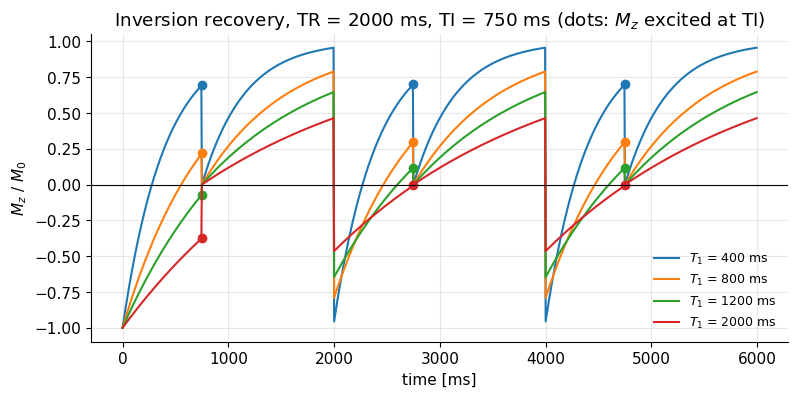

In [17]:
# Inversion recovery: Mz through several repetitions (180 at 0, 90 at TI), ported from the original
def ir_train(T1, TR, TI, NTR=3, dt=0.005, M0=1.0):
    t_all, Mz_all = [], []
    Mz = np.full_like(T1, M0)
    for n in range(NTR):
        Mz = -Mz                                               # 180 deg inversion
        tt = np.arange(0, TI, dt)
        t_all.append(n * TR + tt); Mz_all.append(M0 + (Mz[:, None] - M0) * np.exp(-tt / T1[:, None]))
        Mz = M0 + (Mz - M0) * np.exp(-TI / T1)                 # value at TI (this is what is excited)
        Mz = 0 * Mz                                            # 90 deg excitation (spoiled)
        tt = np.arange(0, TR - TI, dt)
        t_all.append(n * TR + TI + tt); Mz_all.append(M0 + (Mz[:, None] - M0) * np.exp(-tt / T1[:, None]))
        Mz = M0 + (Mz - M0) * np.exp(-(TR - TI) / T1)
    return np.concatenate(t_all), np.concatenate(Mz_all, axis=1)

TR, TI = 2.0, 0.75
t, Mz = ir_train(T1s, TR, TI)
plt.figure(figsize=(9, 4))
for i, T1 in enumerate(T1s):
    plt.plot(t * 1e3, Mz[i], color=f"C{i}", label=f"$T_1$ = {T1*1e3:.0f} ms")
    for n in range(3):
        plt.plot((n * TR + TI) * 1e3, mt.inversion_recovery_signal(TI, TR, 0, T1, 1.0) if n else
                 1 - 2 * np.exp(-TI / T1), "o", color=f"C{i}")
plt.axhline(0, color="k", lw=0.8)
plt.xlabel("time [ms]"); plt.ylabel(r"$M_z$ / $M_0$"); plt.legend(fontsize=9)
plt.title(f"Inversion recovery, TR = {TR*1e3:.0f} ms, TI = {TI*1e3:.0f} ms (dots: $M_z$ excited at TI)")
plt.show()

*Interpretation:* the first repetition starts from full $+M_0$, later ones from the partially recovered value – after that every repetition is identical; the dots (later repetitions) equal the formula. The $T_1$ = 1200 ms tissue is almost exactly at its null point (formula: TI$_{null}$ ≈ 750 ms for TR = 2 s).

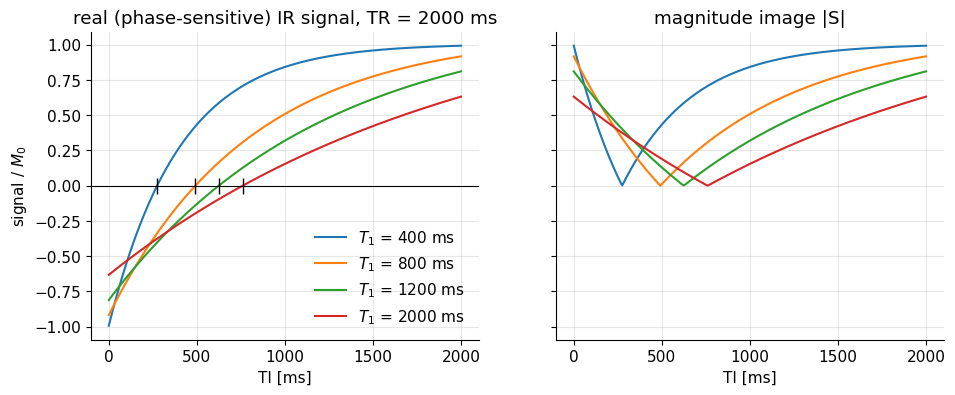

In [18]:
# IR signal versus TI (TR = 2000 ms), ported from the original, plus magnitude version
TR = 2.0
TI = np.linspace(0, 2.0, 400)
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for T1 in T1s:
    s = mt.inversion_recovery_signal(TI, TR, 0, T1, 1.0)
    axs[0].plot(TI * 1e3, s, label=f"$T_1$ = {T1*1e3:.0f} ms")
    axs[1].plot(TI * 1e3, np.abs(s))
    axs[0].plot(ti_null(T1, TR) * 1e3, 0, "k|", ms=12)
axs[0].axhline(0, color="k", lw=0.8)
axs[0].set_title(f"real (phase-sensitive) IR signal, TR = {TR*1e3:.0f} ms"); axs[0].set_xlabel("TI [ms]")
axs[1].set_title("magnitude image |S|"); axs[1].set_xlabel("TI [ms]")
axs[0].set_ylabel(r"signal / $M_0$"); axs[0].legend(); plt.show()

*Interpretation:* most clinical IR images are **magnitude** images (right), so a tissue just before its null point (negative signal) and one just after (positive) can look equally bright – contrast is not monotonic in $T_1$. **Phase-sensitive IR** (PSIR) reconstruction keeps the sign (left) and is used e.g. in cardiac late-gadolinium-enhancement imaging.

> **⚠️ Common confusion:** STIR nulls *anything* with a $T_1$ near fat's, not fat specifically. Gadolinium shortens the $T_1$ of enhancing tissue towards fat's value, so **STIR must not be used after contrast injection**. Chemically selective fat suppression ([D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb)) does not have this problem.

> **🔧 Engineering reality:** a good null needs an accurate 180°. At 3 T and above, the transmit field $B_1^+$ varies by ±20–30 % across the body, so a conventional 180° pulse becomes 140–220° in places and nulling fails. Scanners therefore use **adiabatic** inversion pulses (e.g. hyperbolic secant) that invert fully over a wide range of $B_1^+$ (see [E1 RF Pulses](../pass2_deep_dive/E1_RF_Pulses.ipynb)). FLAIR's long TR (≈ 9 s) would be prohibitively slow if done one slice at a time; scanners interleave many slices within one TR.

## 10. Simulated images with a tissue phantom

`mt.tissue_phantom()` returns maps of $M_0$, $T_1$, $T_2$ for a Shepp–Logan-shaped "head" (fat-like rim, WM, GM, CSF ventricles, small lesions; values ≈ 1.5 T). Applying a signal equation pixel by pixel gives the image the scanner would produce (ignoring k-space effects and noise – those come in [F2](../pass2_deep_dive/F2_K-space.ipynb) and [G2](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb)). The phantom has no separate $T_2^*$ map, so for the gradient-echo images we simply use $T_2^*=T_2$ (in reality $T_2^*$ is shorter).

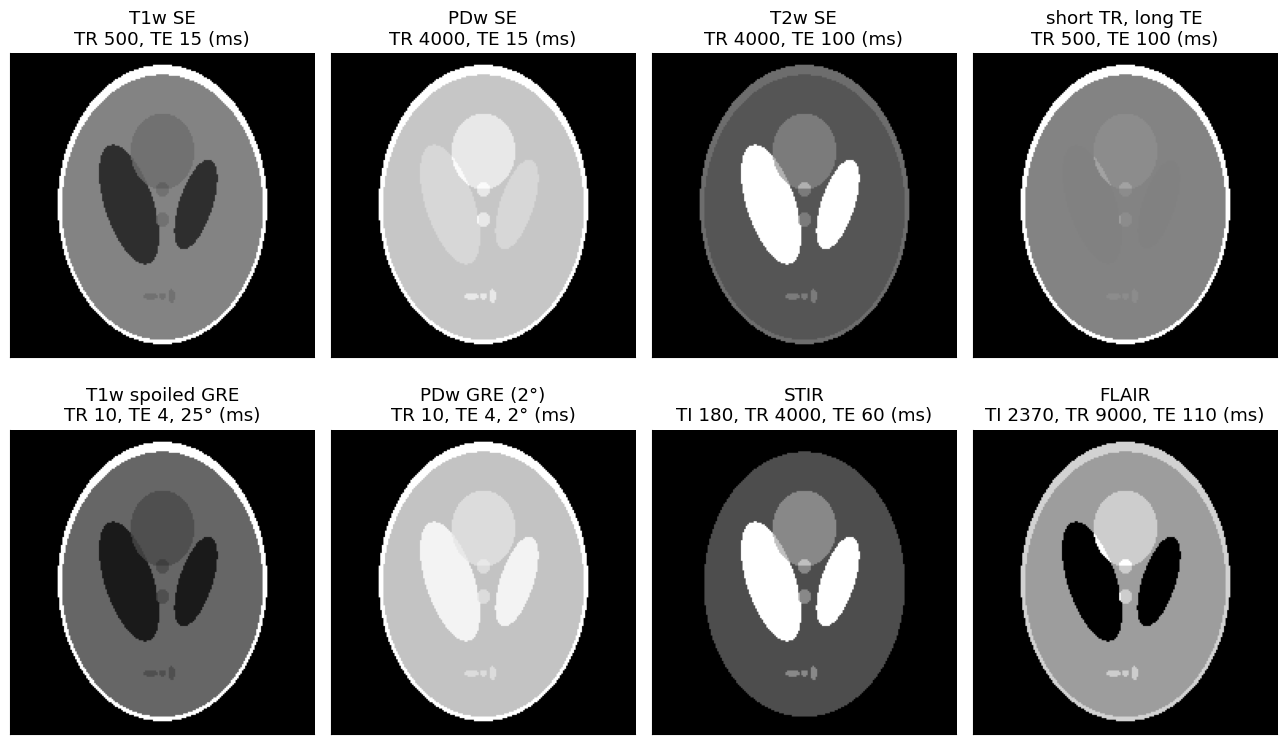

In [19]:
# Simulated images of the tissue phantom for several sequence settings
ph = mt.tissue_phantom(192)
M0, T1map, T2map, lab = ph["M0"], ph["T1"], ph["T2"], ph["labels"]
head = lab > 0
deg = np.pi / 180
protocols = {   # name: (function of maps, parameter text)
    "T1w SE":        (lambda: mt.spin_echo_signal(0.015, 0.500, T1map, T2map, M0), "TR 500, TE 15"),
    "PDw SE":        (lambda: mt.spin_echo_signal(0.015, 4.000, T1map, T2map, M0), "TR 4000, TE 15"),
    "T2w SE":        (lambda: mt.spin_echo_signal(0.100, 4.000, T1map, T2map, M0), "TR 4000, TE 100"),
    "short TR, long TE": (lambda: mt.spin_echo_signal(0.100, 0.500, T1map, T2map, M0), "TR 500, TE 100"),
    "T1w spoiled GRE": (lambda: mt.spoiled_gre_signal(25 * deg, 0.004, 0.010, T1map, T2map, M0), "TR 10, TE 4, 25°"),
    "PDw GRE (2°)":  (lambda: mt.spoiled_gre_signal(2 * deg, 0.004, 0.010, T1map, T2map, M0), "TR 10, TE 4, 2°"),
    "STIR":          (lambda: np.abs(mt.inversion_recovery_signal(0.18, 4.0, 0.060, T1map, T2map, M0)), "TI 180, TR 4000, TE 60"),
    "FLAIR":         (lambda: np.abs(mt.inversion_recovery_signal(2.37, 9.0, 0.110, T1map, T2map, M0)), "TI 2370, TR 9000, TE 110"),
}
images = {}
fig, axs = plt.subplots(2, 4, figsize=(13, 8))
for ax, (name, (f, txt)) in zip(axs.flat, protocols.items()):
    img = f() * head
    images[name] = img
    mt.show_image(img, ax=ax, title=f"{name}\n{txt} (ms)")
plt.tight_layout(); plt.show()

*Interpretation:* the same object gives eight very different pictures: CSF is black (T1w, FLAIR), grey (PDw) or white (T2w); the fat-like rim is bright except on STIR; and "short TR + long TE" is dim with poor contrast, which is why it is not used. (Each image is scaled to its own maximum, as a radiologist's display would be.)

Next we quantify the WM/GM contrast with noise, to make the CNR idea concrete: we add complex Gaussian noise of the same standard deviation $\sigma_n$ to each image (as if all had the same receiver noise) and compute $CNR = |S_{WM}-S_{GM}|/\sigma_n$ and the efficiency $CNR/\sqrt{T_{scan}}$, assuming a 2D acquisition with 192 phase-encoding lines and one slice per TR (an oversimplification for the long-TR scans, which in practice interleave slices).

In [20]:
# CNR and CNR efficiency for WM vs GM in each simulated protocol
sigma = 0.01
TRs = {"T1w SE": 0.5, "PDw SE": 4.0, "T2w SE": 4.0, "short TR, long TE": 0.5, "T1w spoiled GRE": 0.010,
       "PDw GRE (2°)": 0.010, "STIR": 4.0, "FLAIR": 9.0}
rng = np.random.default_rng(1)
print(f"{'protocol':20s} {'S_WM':>6s} {'S_GM':>6s} {'CNR':>6s} {'T_scan [s]':>10s} {'CNR/sqrt(s)':>11s}")
for name, img in images.items():
    noisy = np.abs(mt.add_complex_noise(img, sigma, rng))
    s_wm, s_gm = noisy[lab == 2].mean(), noisy[lab == 3].mean()
    cnr = abs(s_wm - s_gm) / sigma
    T_scan = TRs[name] * 192
    print(f"{name:20s} {s_wm:6.3f} {s_gm:6.3f} {cnr:6.1f} {T_scan:10.1f} {cnr/np.sqrt(T_scan):11.2f}")

protocol               S_WM   S_GM    CNR T_scan [s] CNR/sqrt(s)
T1w SE                0.328  0.282    4.6       96.0        0.47
PDw SE                0.580  0.678    9.8      768.0        0.35
T2w SE                0.201  0.290    8.9      768.0        0.32
short TR, long TE     0.114  0.121    0.7       96.0        0.07
T1w spoiled GRE       0.044  0.035    0.9        1.9        0.67
PDw GRE (2°)          0.025  0.027    0.2        1.9        0.16
STIR                  0.159  0.281   12.2      768.0        0.44
FLAIR                 0.170  0.223    5.2     1728.0        0.13


*Interpretation:* two lessons. (i) Per image, the long-TR protocols (PDw, T2w, STIR) give the highest WM/GM CNR in this phantom: there the higher $M_0$ **and** longer $T_2$ of GM both make GM brighter, so the effects add, whereas in $T_1$-weighting the longer $T_1$ of GM (darker) is partly cancelled by its higher $M_0$ (brighter). Competing factors are common – always check the signs. (ii) Per $\sqrt{\text{time}}$, the short-TR spoiled GRE is the most efficient single-slice protocol, which is one reason 3D $T_1$-weighted brain imaging is done with gradient echoes (FSPGR/MPRAGE). Long-TR 2D scans recover efficiency by exciting ~20–40 other slices during each TR (multi-slice interleaving), which this crude per-slice estimate ignores.

> **🔧 Engineering reality:** how short TR can be is set by the gradient system (how fast the readout and spoilers can be played, see [B4](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb)) and by **SAR**: RF energy deposited per TR grows like $\theta^2$, so short-TR sequences with large flip angles (and spin echoes with many 180° pulses) hit the SAR limit (2 W/kg whole body, normal mode), especially at 3 T where SAR is ~4× that at 1.5 T for the same flip angle ([B6 MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb)). The flip angle you type in is also only *nominal*: $B_1^+$ inhomogeneity makes the true flip angle vary across the image, which modulates $T_1$-weighted contrast at 3 T and 7 T.

### Try it yourself (optional interactive cell)

Move TR, TE and flip angle and watch the spoiled-GRE / spin-echo phantom image and the tissue signals change. The static cell below the widget shows the same plot for the default parameters (widgets are not stored in executed notebooks).

In [21]:
def contrast_explorer(TR_ms=500.0, TE_ms=15.0, flip_deg=90.0):
    """Spoiled-GRE-type signal (equals spin-echo SR for 90 deg) on the tissue phantom."""
    TRs_, TEs_, th = TR_ms * 1e-3, TE_ms * 1e-3, np.deg2rad(flip_deg)
    img = mt.spoiled_gre_signal(th, TEs_, TRs_, T1map, T2map, M0) * head
    fig, axs = plt.subplots(1, 2, figsize=(10, 4))
    mt.show_image(img, ax=axs[0], title=f"TR {TR_ms:.0f} ms, TE {TE_ms:.0f} ms, {flip_deg:.0f}°")
    names = {1: "fat", 2: "WM", 3: "GM", 4: "CSF", 5: "lesion"}
    vals = [img[lab == k].mean() for k in names]
    axs[1].bar(list(names.values()), vals, color=["C3", "C0", "C1", "C2", "C5"])
    axs[1].set_ylabel("signal / M0"); axs[1].set_title("mean signal per tissue")
    plt.tight_layout(); plt.show()

try:
    from ipywidgets import interact, FloatSlider
    interact(contrast_explorer,
             TR_ms=FloatSlider(value=500, min=5, max=6000, step=5),
             TE_ms=FloatSlider(value=15, min=1, max=200, step=1),
             flip_deg=FloatSlider(value=90, min=1, max=90, step=1))
except ImportError:
    print("ipywidgets not available - use the static call below")

interactive(children=(FloatSlider(value=500.0, description='TR_ms', max=6000.0, min=5.0, step=5.0), FloatSlide…

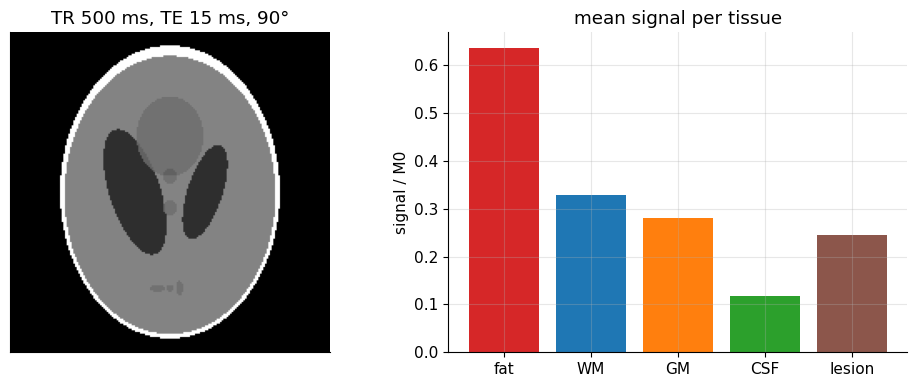

In [22]:
contrast_explorer(TR_ms=500, TE_ms=15, flip_deg=90)   # static default: T1-weighted

*Interpretation:* with the defaults (TR 500 ms, TE 15 ms, 90°) fat > WM > GM > lesion > CSF: a classic $T_1$-weighted ordering. Try TR = 4000, TE = 100 to flip it.

## 11. External simulators

The drcmr.dk web simulators ([CompassMR](https://www.drcmr.dk/CompassMR/) and [BlochSimulator](http://drcmr.dk/BlochSimulator/)) let you apply pulses and watch magnetization in 3D. Everything shown there can be reproduced with `mt.bloch_simulate`, as in Section 7.

## Key takeaways

* Contrast is a **signal difference** between tissues; what matters for detection is $CNR=|S_A-S_B|/\sigma_n$, and for protocol comparison $CNR/\sqrt{T_{scan}}$.
* All basic signal equations follow from two facts: exponential relaxation between pulses and instantaneous rotation by RF pulses; steady state means "$M_z^-$ is the same before every pulse" – a one-line fixed-point equation.
* Spin echo: $S=M_0(1-e^{-TR/T_1})e^{-TE/T_2}$. **TR controls $T_1$ weighting, TE controls $T_2$ weighting.** T1w = short TR/short TE (short $T_1$ bright); T2w = long TR/long TE (long $T_2$ bright); PD = long TR/short TE.
* Spoiled GRE: $S=M_0\sin\theta\,(1-E_1)/(1-E_1\cos\theta)\,e^{-TE/T_2^*}$, valid only with good spoiling (gradient + RF spoiling); the Ernst angle $\theta_E=\arccos E_1\approx\sqrt{2TR/T_1}$ maximizes signal, a larger angle maximizes $T_1$ contrast; very small angles give PD weighting.
* Inversion recovery: $S=M_0(1-2e^{-TI/T_1}+e^{-TR/T_1})e^{-TE/T_2}$; a tissue is nulled at $TI=T_1\ln\frac{2}{1+e^{-TR/T_1}}\approx0.69\,T_1$ (STIR: fat, FLAIR: CSF).
* $T_1$ grows with $B_0$, so the same protocol gives different contrast at 1.5 T and 3 T; SAR and $B_1^+$ inhomogeneity are the main engineering limits on contrast at high field.

## Check your understanding

**1.** A spin-echo scan uses TR = 3000 ms and TE = 20 ms. Which weighting is it, and which is brighter at 1.5 T: WM or GM? CSF or GM?

<details><summary>Answer</summary>

Long TR, short TE → **PD-weighted**. Using the 1.5 T table: $S\approx M_0(1-e^{-3/T_1})e^{-0.02/T_2}$: WM ≈ 0.70·0.98·0.80 ≈ 0.55, GM ≈ 0.80·0.96·0.82 ≈ 0.63, CSF ≈ 1.0·0.53·0.99 ≈ 0.52. So GM > WM, and CSF is similar to or slightly darker than GM because TR = 3 s is not long compared with CSF's $T_1$ ≈ 4 s.

</details>

**2.** Derive the steady-state $M_z^-$ for a spoiled train of 60° pulses with TR = $T_1$. How many pulses until you are within 1 % of steady state?

<details><summary>Answer</summary>

$E_1=e^{-1}=0.368$, $\cos60°=0.5$: $M_{z,ss}=M_0(1-0.368)/(1-0.184)=0.775\,M_0$. The deviation shrinks by $E_1\cos\theta=0.184$ per TR, so $n=\ln0.01/\ln0.184\approx2.7$ → 3 pulses.

</details>

**3.** What is the Ernst angle for TR = 5 ms and $T_1$ = 1400 ms? Would you use it for a $T_1$-weighted scan?

<details><summary>Answer</summary>

$\theta_E=\arccos(e^{-0.005/1.4})\approx\sqrt{2\cdot0.005/1.4}=0.0845$ rad ≈ **4.8°**. It maximizes the signal of that one tissue; for $T_1$ contrast you'd use a larger angle (≈ 8–15°), as Section 6 showed.

</details>

**4.** You want to null CSF ($T_1$ = 4 s) with TR = 6 s. What TI? What if you (wrongly) used $T_1\ln 2$?

<details><summary>Answer</summary>

$TI=4\ln\frac{2}{1+e^{-1.5}}=4\ln(2/1.223)\approx4\cdot0.492=$ **1.97 s**. Using $T_1\ln2=2.77$ s would give $S/M_0=1-2e^{-0.69}+e^{-1.5}=0.223$: CSF would be 22 % of $M_0$ – clearly not suppressed.

</details>

**5.** Why does gradient spoiling alone not reproduce the spoiled-GRE formula?

<details><summary>Answer</summary>

Dephasing transverse magnetization over the voxel is not the same as destroying it. The next RF pulses rotate part of the dephased magnetization back into $z$ and into rephasing pathways (stimulated echoes), so the voxel signal depends on $T_2$ and is higher than the ideal formula (Section 7). Varying the RF phase quadratically (RF spoiling) scrambles these coherent pathways so that their contributions average out.

</details>

**6.** Why must STIR not be used after gadolinium injection?

<details><summary>Answer</summary>

STIR nulls by $T_1$, not by chemistry. Gadolinium shortens $T_1$ of enhancing tissue towards the $T_1$ of fat, so the enhancing lesion would be nulled together with fat – exactly the thing you wanted to see.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Basic Contrast Mechanisms". Changes: added step-by-step derivations (relaxation solutions, exact spin-echo factor, spoiled-GRE fixed point and convergence, Ernst angle and maximum signal, IR with TR term and null point), BPP model, optimal-TE formula, contrast maps, Bloch simulation of spoiling, phantom images, CNR efficiency and an interactive explorer; corrected "T2 always shorter than T1" (→ $T_2\le T_1$), the "relaxation rates" wording, the WM/GM $T_2$ ordering remark at 3 T, and typos.*